In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qutip import (
    Bloch,
    Qobj,
    sigmax,
    sigmay,
    sigmaz,
    expect
)

<h1> Representation of qubits </h1>

The classical bit has deterministically one value at a time: either `0` or `1`, which can also be referred to as `False` or `True`, respectively. Once a qubit is measured, it becomes deterministically either `0` or `1`. However, the great computational potential of qubits lies in the variety of states they can occupy *before* measurement.

In quantum mechanics, the **Bloch sphere** is the geometrical representation of the pure-state space of a two-level quantum mechanical system, which represents the qubit, as illustrated in Fig. [Bloch sphere](#bloch-sphere). Given the orthonormal basis $\{|0\rangle, |1\rangle\}$, any pure state $|\psi\rangle$ of a two-level quantum system can be written as a superposition of the basis vectors $|0\rangle$ and $|1\rangle$:

$$
|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad \alpha, \beta \in \mathbb{C}
$$

where $\alpha$ and $\beta$ are complex coefficients representing the probability amplitudes of the measurement outcomes `0` and `1`, respectively.

Within a two-dimensional Hilbert space $\mathcal{H}_2$, an arbitrary state $|\psi\rangle$ is represented by a unit vector

$$
\begin{pmatrix}
\alpha \\
\beta
\end{pmatrix}
\in \mathbb{C}^2,
$$

where the computational basis states $\{|0\rangle, |1\rangle\}$ correspond to the orthonormal vectors

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix},
\qquad
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}.
$$

A projective measurement in the computational basis $\{|0\rangle, |1\rangle\}$ corresponds to a measurement of the observable $\sigma_z$, effectively projecting $|\psi\rangle$ onto the $Z$-axis of the Bloch representation. The probabilities of obtaining outcomes `0` and `1` are $|\alpha|^2$ and $|\beta|^2$, respectively, satisfying the unity normalization constraint:

$$
|\alpha|^2 + |\beta|^2 = 1.
$$

Qubits are usually represented using the state $|\psi\rangle$ in spherical coordinates:

$$
|\psi\rangle =
\cos\left(\frac{\theta}{2}\right)|0\rangle
+
e^{i\phi}\sin\left(\frac{\theta}{2}\right)|1\rangle
$$

where $0 \leq \theta \leq \pi$ and $0 \leq \phi < 2\pi$ are angles describing the direction of the state vector on the Bloch sphere.

Quantum computation relies on manipulating systems composed of multiple interacting qubits. Unlike classical bits, which combine to form binary strings representing a single configuration at any given time, quantum systems are described by the **tensor product** of the individual qubit Hilbert spaces.

For a quantum register consisting of $n$ qubits, the state space becomes the tensor product of the individual qubit spaces:

$$
\mathcal{H}^{(n)} = \bigotimes_{i=1}^{n}\mathcal{H}_2
$$

Consequently, the dimension of the composite Hilbert space grows exponentially according to:

$$
\dim\left(\mathcal{H}^{(n)}\right) = 2^n
$$

A general pure state of an $n$-qubit register $|\Psi\rangle$ is expressed as:

$$
|\Psi\rangle = \sum_{i=0}^{2^n-1}\alpha_i|i\rangle
$$

where $|i\rangle$ denotes the computational basis state corresponding to the binary representation of the integer $i$, and the complex probability amplitudes satisfy the normalization condition:

$$
\sum_{i=0}^{2^n-1}|\alpha_i|^2 = 1.
$$

The state vector of an $n$-qubit register $|\Psi\rangle$ is therefore represented as:

$$
|\Psi\rangle =
\begin{bmatrix}
\alpha_0 \\
\alpha_1 \\
\vdots \\
\alpha_{2^n-1}
\end{bmatrix}
$$

where each element corresponds to the probability amplitude associated with one computational basis state.

As an illustrative example, the computational basis states of a two-qubit system are obtained through the tensor product of two individual qubits:

$$
|00\rangle =
\begin{bmatrix}
1 \\
0
\end{bmatrix}
\otimes
\begin{bmatrix}
1 \\
0
\end{bmatrix}
=
\begin{bmatrix}
1 \\
0 \\
0 \\
0
\end{bmatrix}
$$

$$
|01\rangle =
\begin{bmatrix}
1 \\
0
\end{bmatrix}
\otimes
\begin{bmatrix}
0 \\
1
\end{bmatrix}
=
\begin{bmatrix}
0 \\
1 \\
0 \\
0
\end{bmatrix}
$$

$$
|10\rangle =
\begin{bmatrix}
0 \\
1
\end{bmatrix}
\otimes
\begin{bmatrix}
1 \\
0
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0 \\
1 \\
0
\end{bmatrix}
$$

$$
|11\rangle =
\begin{bmatrix}
0 \\
1
\end{bmatrix}
\otimes
\begin{bmatrix}
0 \\
1
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0 \\
0 \\
1
\end{bmatrix}
$$

Accordingly, an arbitrary two-qubit quantum state is represented as:

$$
|\Psi\rangle =
\alpha_{00}|00\rangle
+
\alpha_{01}|01\rangle
+
\alpha_{10}|10\rangle
+
\alpha_{11}|11\rangle
$$

or equivalently:

$$
|\Psi\rangle =
\begin{bmatrix}
\alpha_{00} \\
\alpha_{01} \\
\alpha_{10} \\
\alpha_{11}
\end{bmatrix}
$$

where the amplitudes satisfy:

$$
|\alpha_{00}|^2
+
|\alpha_{01}|^2
+
|\alpha_{10}|^2
+
|\alpha_{11}|^2
= 1.
$$

<h1> Properties of Qubits </h1>

The main properties of qubits are the following:

- **Superposition:**

  Superposition is setting the quantum state of a qubit to a linear combination of $|0\rangle$ and $|1\rangle$, which constitutes the main difference between a logical bit and a quantum bit.

- **Entanglement:**

  Entanglement is a uniquely quantum mechanical correlation that can exist between two or more qubits, such that the state of each individual qubit can no longer be described independently of the others. Instead, the composite system must be represented by a joint quantum state. In an entangled system, measurement results show correlations that cannot be explained by classical probability theory, and this correlation is sustained regardless of the spatial separation between the qubits.

  Mathematically, consider two qubits A and B with states $|\psi\rangle_A = \alpha|0\rangle+\beta|1\rangle$ and $|\psi\rangle_B = \gamma|0\rangle+\delta|1\rangle$, respectively. If the combined system can be written as a tensor product of individual quantum states,

  $$
  |\Psi\rangle_{AB}=|\psi\rangle_A\otimes|\psi\rangle_B
  $$

  then the two qubits A and B are not entangled. An entangled $|\Psi\rangle_{AB}$ state is one that cannot be factorized into individual qubit states. Within an entangled system, measuring one qubit instantaneously determines the state of the overall system and constrains the possible outcomes of measurements performed on the remaining qubits.

  A canonical example is the Bell state:

  $$
  |\Phi^+\rangle=\frac{1}{\sqrt{2}}\left(|00\rangle+|11\rangle\right)
  $$

  This state cannot be rewritten as $|\psi\rangle_A \otimes |\psi\rangle_B$ for any single-qubit states $|\psi\rangle_A$ and $|\psi\rangle_B$. The Bell state illustrates quantum entanglement: before measurement, neither qubit has a definite individual value. However, measuring one qubit immediately determines the measurement outcome probabilities of the other. For example, the probability of measuring the state $|00\rangle$ is the same as that of measuring the state $|11\rangle$:

  $$
  P(|00\rangle)=P(|11\rangle)=\frac{1}{2}
  $$

  while

  $$
  P(|01\rangle)=P(|10\rangle)=0
  $$

  meaning that both qubits always collapse into identical outcomes despite being initially represented as distinct physical systems, or distant qubits.

  Entanglement is a fundamental resource for quantum computing and communication, enabling quantum teleportation, distributed quantum operations, quantum error correction, and computational speedups, as will be showcased in the following sections.

- **Interference:**

  Interference is the phenomenon by which probability amplitudes of different computational outcomes combine constructively or destructively during the evolution of a quantum system. The superposition of quantum states allows amplitudes corresponding to correct solutions to reinforce one another while suppressing incorrect outcomes. Quantum algorithms rely on interference to amplify the amplitude of correct answers, and therefore amplify the probability of their measurement at the end of the computation process.

- **Measurement:**

  As defined in [Representation of Qubits](#representation-of-qubits), prior to performing measurement on a qubit, its quantum state is in a superposition of $|0\rangle$ and $|1\rangle$. Measurement is the action that collapses the qubit state and forces it to be either $|0\rangle$ or $|1\rangle$. The measured outcome is deterministically `0` or `1`.

<h1> Quantum Operations and Circuits </h1>

Within the circuit model of computation, quantum computation proceeds through the application of quantum operations, commonly referred to as *quantum gates*, which manipulate the state of one or more qubits. Quantum gates are represented by unitary matrices that preserve the norm of the quantum state, satisfying:

$$
U^{\dagger}U = UU^{\dagger}=I
$$

where $U^{\dagger}$ denotes the conjugate transpose of $U$, and $I$ is the identity matrix. Given a quantum state $|\psi\rangle$, the application of a quantum gate transforms the state according to:

$$
|\psi'\rangle = U|\psi\rangle
$$

For a single qubit, quantum gates are represented by $2 \times 2$ unitary matrices. Among the most fundamental gates we find the Pauli gates, the Hadamard gate, and the phase gates.

For instance, the Pauli-X gate acts as the quantum equivalent of a classical NOT operation by exchanging the computational basis states:

$$
X=
\begin{bmatrix}
0 & 1\\
1 & 0
\end{bmatrix}
$$

such that:

$$
X|0\rangle = |1\rangle,
\qquad
X|1\rangle = |0\rangle
$$

Similarly, the Pauli-Y and Pauli-Z gates are defined as:

$$
Y=
\begin{bmatrix}
0 & -i\\
i & 0
\end{bmatrix},
\qquad
Z=
\begin{bmatrix}
1 & 0\\
0 & -1
\end{bmatrix}
$$

The Pauli-Y gate introduces a relative phase while exchanging the computational basis states, whereas the Pauli-Z gate preserves the basis states and applies a phase shift of $\pi$ to the $|1\rangle$ state, such that:

$$
Z|0\rangle = |0\rangle,
\qquad
Z|1\rangle = -|1\rangle
$$

Among the most important single-qubit operations is the Hadamard gate, represented as:

$$
H=\frac{1}{\sqrt{2}}
\begin{bmatrix}
1 & 1\\
1 & -1
\end{bmatrix}
$$

which transforms computational basis states into equal superposition states, commonly referred to as $|+\rangle$ and $|-\rangle$:

$$
H|0\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}} = |+\rangle
$$

$$
H|1\rangle = \frac{|0\rangle-|1\rangle}{\sqrt{2}} = |-\rangle
$$

The Hadamard gate therefore plays a fundamental role in quantum algorithms by enabling quantum parallelism through the creation of coherent superposition states.

Quantum operations inherently extend to systems containing multiple qubits. In this case, gates are represented by $2^n \times 2^n$ unitary matrices acting on the composite Hilbert space $\mathcal{H}^{(n)}$. Gates operating on different qubits are constructed using the tensor product of the corresponding single-qubit operators. For instance, applying a Hadamard gate to the first qubit of a two-qubit register is represented as:

$$
H \otimes I
$$

where $I$ denotes the $2\times2$ identity matrix.

Multi-qubit quantum gates enable interactions between qubits, particularly quantum entanglement. A fundamental two-qubit gate is the controlled-NOT (CNOT) gate, whose matrix representation is:

$$
\mathrm{CNOT}=
\begin{bmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 1 & 0
\end{bmatrix}
$$

The CNOT gate flips the target qubit whenever the control qubit is in the state $|1\rangle$, so we find the following transformations:

$$
\mathrm{CNOT}(|00\rangle) \rightarrow |00\rangle
$$

$$
\mathrm{CNOT}(|01\rangle) \rightarrow |01\rangle
$$

$$
\mathrm{CNOT}(|10\rangle) \rightarrow |11\rangle
$$

$$
\mathrm{CNOT}(|11\rangle) \rightarrow |10\rangle
$$

The initial state of the $n$-qubit quantum register is typically prepared in one of the computational basis states, usually $|0\rangle^{\otimes n}$. At the end of the computation process, one or more qubits are measured, collapsing the quantum state onto the computational basis and producing classical outcomes as binary strings according to the corresponding probability distribution.

A graphical representation of a two-qubit quantum circuit is depicted below. The computational complexity of a quantum circuit is characterized by metrics such as the total gate count, the circuit depth, and the number of qubits required to solve a given problem. These metrics are particularly important in the noisy intermediate-scale quantum (NISQ) era, where decoherence, gate errors, and limited qubit connectivity constrain the successful execution of quantum circuits.

In [44]:
def random_qubit_state():
    """Generate a Haar-random single-qubit pure state."""

    amplitudes = (
        np.random.randn(2) +
        1j * np.random.randn(2)
    )

    amplitudes /= np.linalg.norm(amplitudes)

    return Qobj(amplitudes.reshape(2, 1))

# Define quantum rotations

def rotation(pauli, theta):
    """
    Rotation around a Bloch sphere axis.

    R_axis(theta) = exp(-i * theta * sigma_axis / 2)
    """

    return (-1j * theta / 2 * pauli).expm()

In [45]:
# Pauli operators
X = sigmax()
Y = sigmay()
Z = sigmaz()

In [46]:
def bloch_coordinates(state):
    """Calculate the expectation values of Pauli operators."""

    x = np.real(expect(X, state))
    y = np.real(expect(Y, state))
    z = np.real(expect(Z, state))

    return np.array([x, y, z])

In [47]:
operations = [
    ("Initial state", None),

    ("Rotation X (60°)", rotation(X, np.pi / 3)),

    ("Pauli-X (180°)", X),

    ("Rotation Y (45°)", rotation(Y, np.pi / 4)),

    ("Pauli-Y (180°)", Y),

    ("Rotation Z (90°)", rotation(Z, np.pi / 2)),

    ("Pauli-Z (180°)", Z),
]

In [51]:
psi = random_qubit_state()

states = [psi]
vectors = [bloch_coordinates(psi)]

In [52]:
for name, gate in operations[1:]:

    psi = gate * psi

    states.append(psi)
    vectors.append(bloch_coordinates(psi))

    x, y, z = vectors[-1]

    print(
        f"{name:25s} "
        f"X={x:+.4f}, "
        f"Y={y:+.4f}, "
        f"Z={z:+.4f}"
    )

Rotation X (60°)          X=+0.4452, Y=+0.4642, Z=-0.7657
Pauli-X (180°)            X=+0.4452, Y=-0.4642, Z=+0.7657
Rotation Y (45°)          X=+0.8563, Y=-0.4642, Z=+0.2266
Pauli-Y (180°)            X=-0.8563, Y=-0.4642, Z=-0.2266
Rotation Z (90°)          X=+0.4642, Y=-0.8563, Z=-0.2266
Pauli-Z (180°)            X=-0.4642, Y=+0.8563, Z=-0.2266


In [56]:

from matplotlib.animation import FuncAnimation
# Create figure and Bloch sphere
fig = plt.figure(figsize=(7, 7))
bloch = Bloch(fig=fig)

# Animation update function
def update(frame):
    bloch.clear()

    # Display the trajectory up to the current operation
    bloch.add_points(np.array(vectors[:frame+1]).T, meth='l')

    # Display current state vector
    bloch.add_vectors(vectors[frame])

    # Add initial state vector
    if frame > 0:
        bloch.add_vectors(vectors[0])

    bloch.render()

    return fig.axes

# Create animation
ani = FuncAnimation(
    fig,
    update,
    frames=len(vectors),
    interval=800,
    repeat=True,
    blit=False
)

plt.close(fig)

In [57]:
from IPython.display import HTML

HTML(ani.to_jshtml())

<h1> Quantum Circuit and Measurement Results <h1>

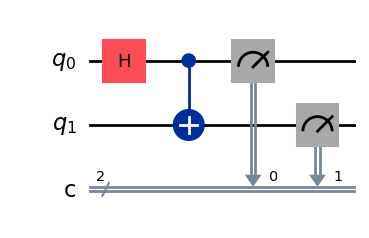

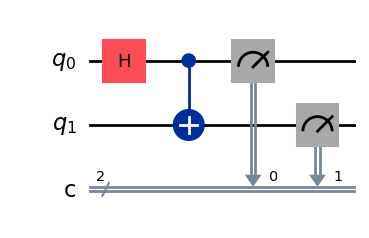

In [59]:
from qiskit import QuantumCircuit

# Create a two-qubit, two-classical-bit circuit
qc = QuantumCircuit(2, 2)

# Hadamard gate: create superposition
qc.h(0)

# CNOT gate: generate entanglement
qc.cx(0, 1)

# Measure both qubits
qc.measure([0, 1], [0, 1])

# Visualize circuit
display(qc.draw("mpl"))


In [60]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize simulator
simulator = AerSimulator()

# Transpile circuit for simulator
qc_sim = transpile(qc, simulator)

# Execute circuit
shots = 4096

job_sim = simulator.run(qc_sim, shots=shots)

# Retrieve results
result_sim = job_sim.result()
counts_sim = result_sim.get_counts()

print("Simulator results:")
print(counts_sim)


Simulator results:
{'11': 2027, '00': 2069}


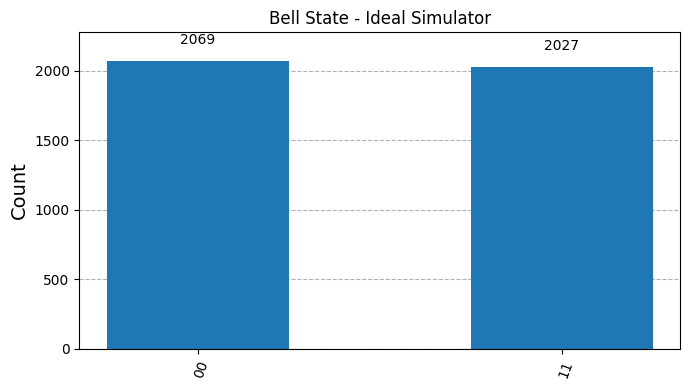

In [61]:
# Visualize measurement outcomes
plot_histogram(
    counts_sim,
    title="Bell State - Ideal Simulator",
    figsize=(7, 4)
)

plt.show()

In [12]:
# Authenticate using saved credentials
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService()

# Find the least busy operational quantum processor
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2
)

print("Selected quantum processor:", backend.name)
print("Number of qubits:", backend.num_qubits)

Selected quantum processor: ibm_fez
Number of qubits: 156


Transpiled circuit:


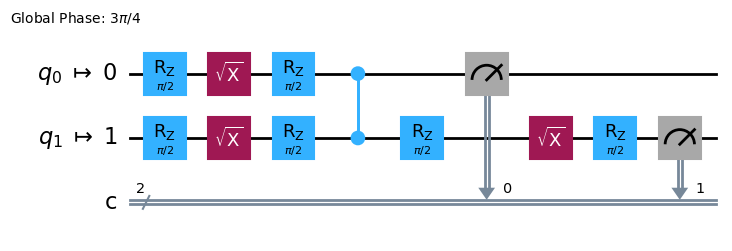


Circuit operations:
OrderedDict([('rz', 6), ('sx', 3), ('measure', 2), ('cz', 1)])


In [13]:
from qiskit.transpiler import generate_preset_pass_manager

# Generate hardware-specific transpilation pipeline
pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

# Transpile circuit
isa_circuit = pm.run(qc)

print("Transpiled circuit:")
display(isa_circuit.draw("mpl", idle_wires=False))

print("\nCircuit operations:")
print(isa_circuit.count_ops())

In [14]:
from qiskit_ibm_runtime.executor_sampler import Sampler

# Initialize Sampler
sampler = Sampler(mode=backend)

# Submit circuit
job_hw = sampler.run(
    [isa_circuit],
    shots=4096
)

# Display job ID
print("Job ID:", job_hw.job_id())
print("Job status:", job_hw.status())

# Wait for execution and retrieve results
result_hw = job_hw.result()

# Extract measurement counts
counts_hw = result_hw[0].data.c.get_counts()

print("\nIBM Quantum hardware results:")
print(counts_hw)

Job ID: dbsd3s8k09pc73b01apg
Job status: QUEUED

IBM Quantum hardware results:
{'11': 1884, '00': 1974, '10': 142, '01': 96}


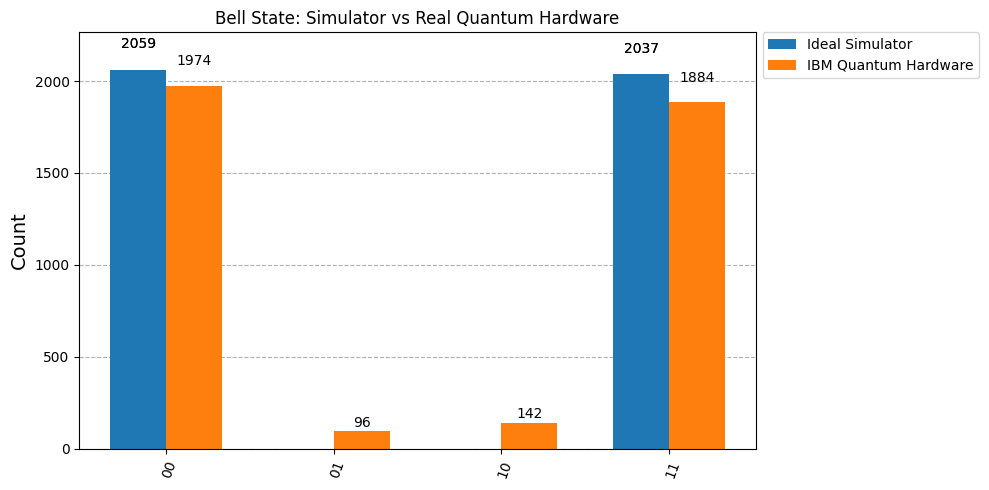

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

# Compare both measurement distributions
plot_histogram(
    [counts_sim, counts_hw],
    legend=["Ideal Simulator", "IBM Quantum Hardware"],
    title="Bell State: Simulator vs Real Quantum Hardware",
    figsize=(10, 5)
)

plt.show()

<h1> Quantum Algorithms </h1>

Several quantum algorithms demonstrating a theoretical or practical quantum advantage have been proposed. Small-scale instances of these algorithms have been implemented on NISQ devices, although no defensible quantum advantage has been achieved yet. This has provided proof-of-concept validations of quantum computation on early-stage hardware and has established the algorithmic foundations of the field and validated important computational primitives, such as entanglement.

As quantum hardware progresses toward fault-tolerant quantum computing (FTQC) systems, these algorithms are expected to evolve into practical applications or serve as fundamental subroutines within larger and more sophisticated quantum algorithms capable of delivering a meaningful computational advantage over classical approaches.

Among the first quantum algorithms formulated is the **Deutsch-Jozsa algorithm** [1], proposed by David Deutsch and Richard Jozsa in 1992 to evaluate if a function is balanced within one trial, while the classical approach requires applying at least two instructions to obtain the same result. This algorithm was the first proof of quantum algorithms' efficiency in comparison to classical problem-solving approaches. It is also the foundation of other algorithms, such as the Bernstein-Vazirani algorithm [2].

In 1994, Peter Shor presented **Shor's algorithm** [3] for factorization of large prime numbers, which is a hybrid classical-quantum algorithm that holds the potential to disrupt fields of cybersecurity and encryption by factoring large prime numbers.

In 1996, Lov Grover invented **Grover's search algorithm** [4], which is used for element search in unstructured lists of data. Grover's algorithm demonstrates a quadratic speedup to solve a given search problem, compared to its classical counterparts.

Other quantum algorithms include the **Variational Quantum Eigensolver (VQE)** [5] for molecular simulations and the **Quantum Approximate Optimization Algorithm (QAOA)** [6] for optimization.

The quantum circuits of Grover's, VQE, and QAOA are represented in the [Appendix: Implemented Circuits](#implemeted-circuits).

The development of new quantum algorithms is evolving fast, and a number of applications have emerged to endorse the efficiency of quantum approaches, especially in fields of optimization [7], molecular simulations [8, 9], machine learning [10], and finance [11].

---

### References

Replace the numbered references below with the corresponding entries from your bibliography:

1. Deutsch and Jozsa (1992) — `deutsch1992rapid`
2. Bernstein and Vazirani (1993) — `bernstein1993quantum`
3. Shor (1999) — `shor1999polynomial`
4. Grover (1996) — `grover1996fast`
5. VQE — `bharti2022noisy`
6. QAOA — `farhi2014quantum`
7. Optimization — `abbas2024challenges`
8. Molecular simulations — `Low2019`
9. Molecular simulations — `Peruzzo2014`
10. Machine learning — `Biamonte2017`
11. Finance — `Woerner2019`

<h1> Grover's Search Algorithm </h1>

Grover's algorithm is a quantum search algorithm designed to find a specific element in an unstructured search space. It provides a **quadratic speedup** over classical search by exploiting quantum superposition and interference.

In this example, we use **4 qubits to search among 16 possible states**, with `1011` as the target state.

### 1. Initialization: Creating a Superposition

The circuit starts with all qubits in the ground state:

$$
|0000\rangle
$$

We apply a Hadamard gate to each qubit, creating an equal superposition of all 16 possible states:

$$
|\psi\rangle = \frac{1}{4}\sum_{x=0}^{15}|x\rangle
$$

At this stage, every possible answer has an equal probability of being measured (6.25%).

In [ ]:
n = 4
target = "1011"
shots = 2048

### 2. Oracle: Marking the Target State

The quantum oracle identifies the target state, `1011`, by applying a phase flip to its amplitude:

$$
|1011\rangle \rightarrow -|1011\rangle
$$

All other states remain unchanged.

The oracle does not directly reveal the solution. Instead, it marks the correct answer through a change in its phase.

In [20]:
# Phase oracle: flip the phase of the target state
def oracle(qc, target):
    # Apply X gates to qubits corresponding to 0 bits
    for i, bit in enumerate(reversed(target)):
        if bit == "0":
            qc.x(i)

    # Multi-controlled Z gate
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)

    # Undo the X gates
    for i, bit in enumerate(reversed(target)):
        if bit == "0":
            qc.x(i)

### 3. Diffusion: Amplitude Amplification

The diffusion operator amplifies the probability amplitude of the marked state through quantum interference.

It performs an inversion about the average amplitude, increasing the amplitude of the target state while decreasing the amplitudes of the other states.

The oracle and diffusion operators are applied twice in this example, progressively increasing the probability of measuring the target state.

In [21]:
# Grover diffusion operator
def diffuser(qc):
    qc.h(range(n))
    qc.x(range(n))

    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)

    qc.x(range(n))
    qc.h(range(n))

In [24]:
# Build Grover's circuit
qc = QuantumCircuit(n, n)

# Step 1: Create an equal superposition
qc.h(range(n))
qc.barrier()

# Step 2: Apply two Grover iterations
for _ in range(2):
    oracle(qc, target)
    qc.barrier()
    diffuser(qc)
    qc.barrier()


### 4. Measurement: Obtaining the Solution

Finally, we measure all four qubits in the computational basis.

After two Grover iterations, the probability of obtaining the target state `1011` is approximately **96.1%**, compared with an initial probability of only 6.25%.

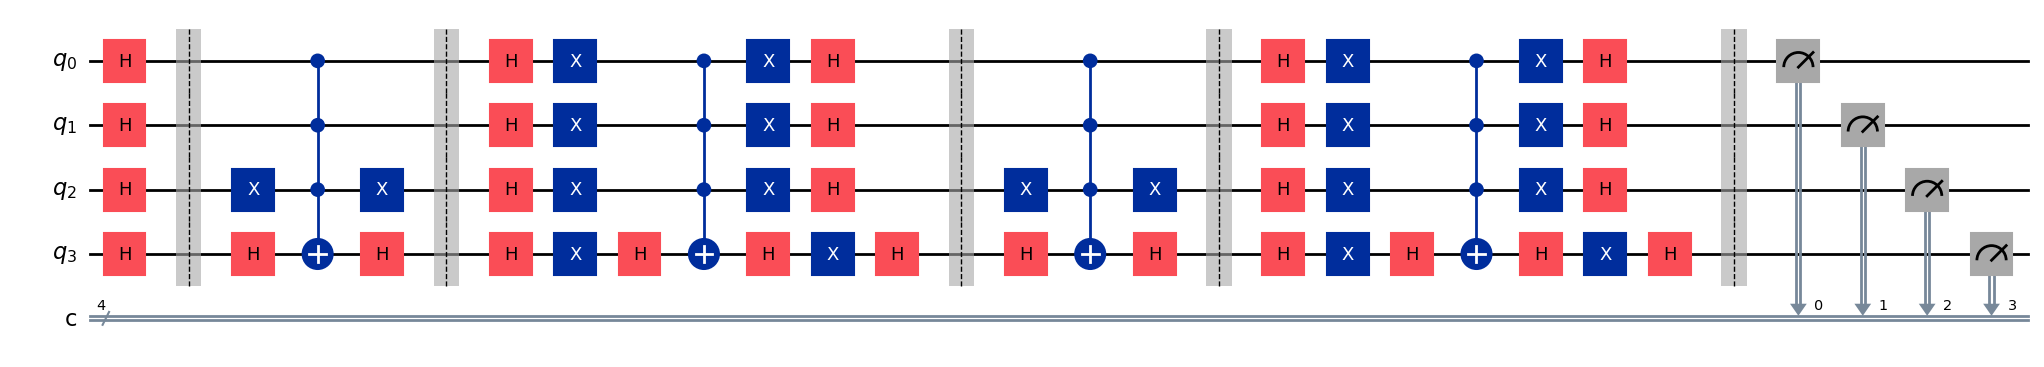

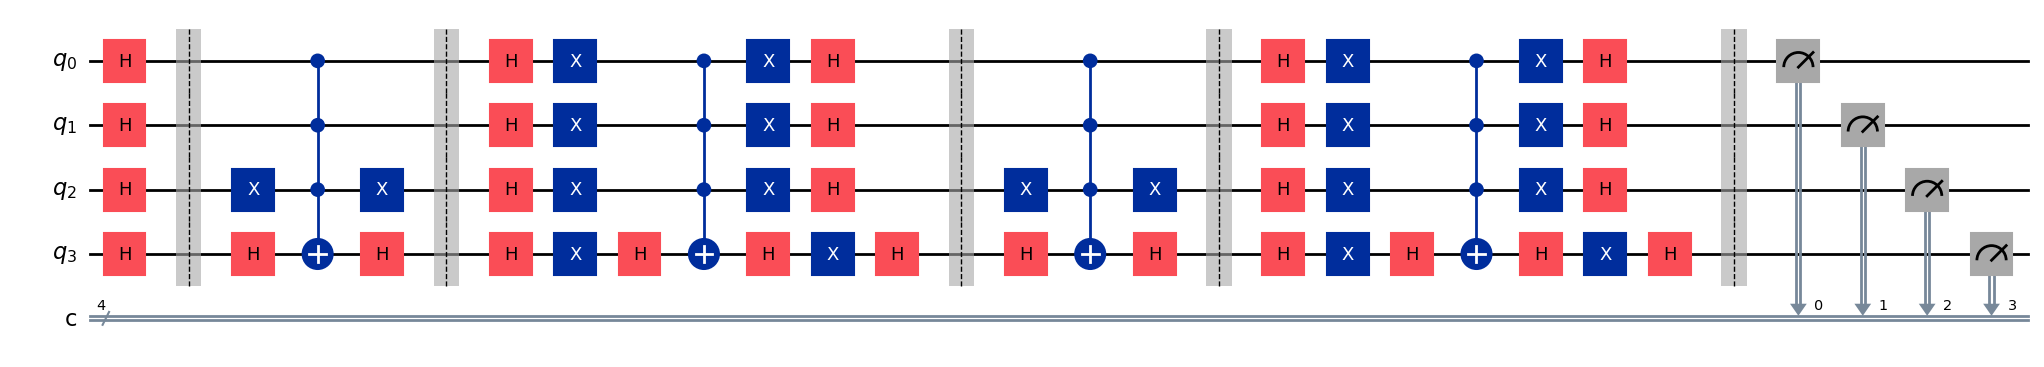

In [25]:
# Step 3: Measure all qubits
qc.measure(range(n), range(n))

# Display the circuit
display(qc.draw("mpl", fold=-1))

In [26]:
# Run on the Aer simulator
simulator = AerSimulator()
compiled_circuit = transpile(qc, simulator)

result = simulator.run(
    compiled_circuit,
    shots=shots
).result()

counts = result.get_counts()

# Display measurement results
print("Measurement results:", counts)
print("Target state:", target)
print("Success probability:",
      round(counts.get(target, 0) / shots * 100, 2), "%")

Measurement results: {'0010': 8, '1000': 7, '0110': 13, '1111': 8, '1101': 16, '0101': 15, '1010': 11, '1001': 20, '0000': 10, '0100': 17, '1100': 15, '1110': 14, '0001': 8, '0011': 8, '0111': 15, '1011': 1863}
Target state: 1011
Success probability: 90.97 %


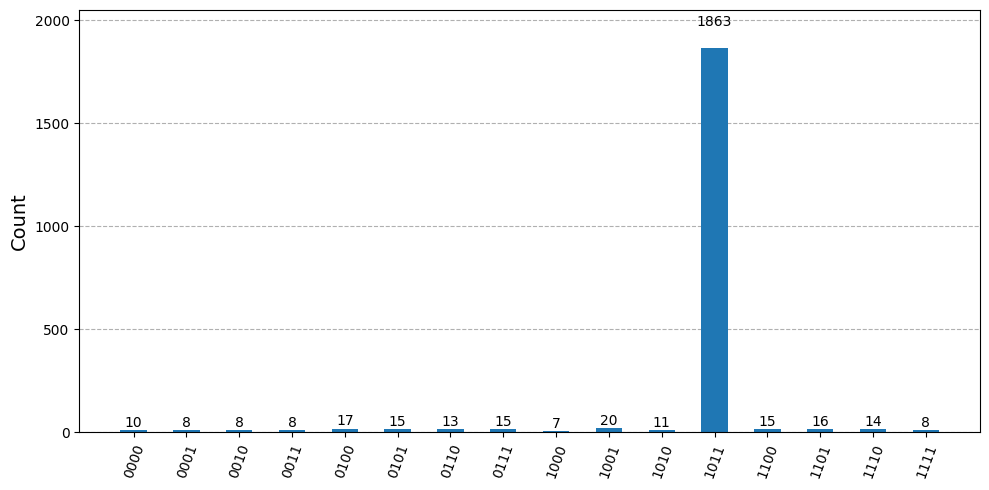

In [27]:
# Plot the measurement histogram
plot_histogram(counts, figsize=(10, 5))
plt.show()

### 5. Where Does the Quantum Advantage Come From?

For an unstructured search space containing $N$ elements:

- A classical algorithm requires $O(N)$ queries in the worst case.
- Grover's algorithm requires approximately $O(\sqrt{N})$ oracle queries.

This quadratic speedup comes from the ability to manipulate quantum probability amplitudes through superposition and interference, rather than examining individual candidates sequentially.